In [30]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import Model
from tensorflow.keras import layers

In [3]:
print(tf.__version__)

2.21.0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/creditcard.csv")

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

X_train_normal = X_train_scaled[y_train.values == 0]

print(X_train_normal.shape)

(199020, 30)


In [5]:
input_dim = X_train_normal.shape[1]

input_layer = layers.Input(shape=(input_dim,))

# Encoder
x = layers.Dense(64, activation="relu")(input_layer)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)

latent = layers.Dense(8, activation="relu")(x)

# Decoder
x = layers.Dense(16, activation="relu")(latent)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)

output_layer = layers.Dense(
    input_dim,
    activation="linear"
)(x)

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

In [6]:
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 30)             │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,478 (37.02 KB)

 Trainable params: 9,478 (37.02 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
autoencoder.compile(
    optimizer="adam",
    loss="mae"
)

In [8]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.4727 - val_loss: 0.3858
Epoch 2/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3641 - val_loss: 0.3426
Epoch 3/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3323 - val_loss: 0.3211
Epoch 4/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3181 - val_loss: 0.3118
Epoch 5/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.3102 - val_loss: 0.3054
Epoch 6/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3045 - val_loss: 0.3004
Epoch 7/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3001 - val_loss: 0.2967
Epoch 8/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2963 - val_loss: 0.2930
Epoch 9/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.2927 - val_loss: 0.2888
Epoch 10/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.2892 - val_loss: 0.2844
Epoch 11/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.2859 - val_loss: 0.2809
Epoch 12/50
700/700 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step

In [9]:
train_reconstructed = autoencoder.predict(
    X_train_normal
)

6220/6220 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step


In [10]:
train_error = np.mean(
    np.abs(
        X_train_normal - train_reconstructed
    ),
    axis=1
)


In [11]:
threshold = np.percentile(
    train_error,
    99
)

print("Threshold:", threshold)


Threshold: 1.1721364609701026


In [12]:
test_reconstructed = autoencoder.predict(
    X_test_scaled
)

1336/1336 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [13]:
test_error = np.mean(
    np.abs(
        X_test_scaled - test_reconstructed
    ),
    axis=1
)

In [14]:
y_pred = (
    test_error > threshold
).astype(int)

In [15]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

In [16]:
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     42648
           1       0.12      0.78      0.22        74

    accuracy                           0.99     42722
   macro avg       0.56      0.89      0.61     42722
weighted avg       1.00      0.99      0.99     42722



In [17]:
print("Precision:",
      precision_score(y_test, y_pred))

print("Recall:",
      recall_score(y_test, y_pred))

print("F1:",
      f1_score(y_test, y_pred))

Precision: 0.125
Recall: 0.7837837837837838
F1: 0.21561338289962825


In [18]:
print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        test_error
    )
)

PR-AUC: 0.2976017816361898


In [19]:
threshold = np.percentile(train_error, 99)

In [20]:
val_reconstructed = autoencoder.predict(X_val_scaled)

val_error = np.mean(
    np.abs(X_val_scaled - val_reconstructed),
    axis=1
)

1336/1336 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.percentile(
    val_error,
    np.arange(90, 100, 0.5)
)

results = []

for threshold in thresholds:

    y_val_pred = (
        val_error > threshold
    ).astype(int)

    precision = precision_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_val_pred,
        zero_division=0
    )

    results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

In [22]:
results_df = pd.DataFrame(results)

results_df.head()

,threshold,precision,recall,f1
0,0.418007,0.014747,0.851351,0.028992
1,0.426377,0.015521,0.851351,0.030486
2,0.436866,0.016385,0.851351,0.032151
3,0.446743,0.017346,0.851351,0.033999
4,0.458030,0.018139,0.837838,0.035510


In [23]:
best_result = results_df.loc[
    results_df["f1"].idxmax()
]

print(best_result)

threshold    1.790132
precision    0.210280
recall       0.608108
f1           0.312500
Name: 19, dtype: float64


In [24]:
best_threshold = best_result["threshold"]

print("Best threshold:", best_threshold)

Best threshold: 1.7901317023182532


In [25]:
import joblib

joblib.dump(
    best_threshold,
    "../models/threshold.pkl"
)

['../models/threshold.pkl']

In [26]:
test_pred = (
    test_error > best_threshold
).astype(int)

In [27]:
print(
    classification_report(
        y_test,
        test_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42648
           1       0.22      0.57      0.31        74

    accuracy                           1.00     42722
   macro avg       0.61      0.78      0.66     42722
weighted avg       1.00      1.00      1.00     42722



In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    test_pred
)

print(cm)

[[42495   153]
 [   32    42]]


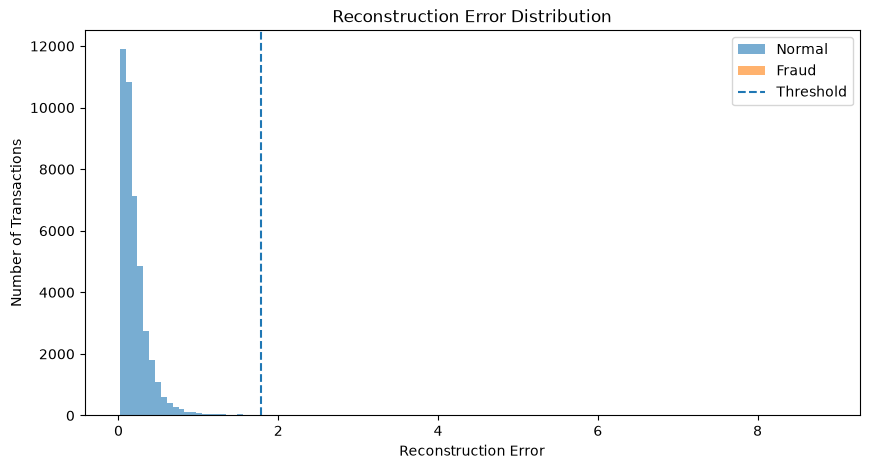

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(
    test_error[y_test == 0],
    bins=100,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    test_error[y_test == 1],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.title("Reconstruction Error Distribution")

plt.legend()
plt.show()

In [32]:
autoencoder.save("../models/fraud_autoencoder.keras")

In [33]:
import joblib

joblib.dump(
    scaler,
    "../models/scaler.pkl"
)
joblib.dump(
    best_threshold,
    "../models/threshold.pkl"
)

['../models/threshold.pkl']

In [34]:
from tensorflow.keras.models import load_model
import joblib

model = load_model(
    "../models/fraud_autoencoder.keras"
)

loaded_scaler = joblib.load(
    "../models/scaler.pkl"
)

loaded_threshold = joblib.load(
    "../models/threshold.pkl"
)

print("Model loaded successfully")
print("Threshold:", loaded_threshold)

Model loaded successfully
Threshold: 1.7901317023182532


In [1]:
def predict_transaction(transaction):

    # Scale transaction
    transaction_scaled = loaded_scaler.transform(
        transaction
    )

    # Reconstruct transaction
    reconstructed = model.predict(
        transaction_scaled,
        verbose=0
    )

    # Calculate reconstruction error
    error = np.mean(
        np.abs(
            transaction_scaled - reconstructed
        ),
        axis=1
    )

    # Determine prediction
    prediction = (
        error > loaded_threshold
    ).astype(int)

    return prediction, error

In [2]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import load_model

# Load dataset
df = pd.read_csv("../data/creditcard.csv")

# Separate features and actual labels
X = df.drop("Class", axis=1)
y = df["Class"]

# Recreate the original split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Load saved artifacts
model = load_model("../models/fraud_autoencoder.keras")
scaler = joblib.load("../models/scaler.pkl")
threshold = joblib.load("../models/threshold.pkl")

# Scale test data using the fitted training scaler
X_test_scaled = scaler.transform(X_test)

print("Model loaded successfully!")
print("Threshold:", threshold)
print("Test transactions:", len(X_test))

Model loaded successfully!
Threshold: 1.7901317023182532
Test transactions: 42722


In [3]:
# Reconstruct test transactions
test_reconstructed = model.predict(
    X_test_scaled,
    verbose=0
)

# Calculate one reconstruction error per transaction
test_error = np.mean(
    np.abs(X_test_scaled - test_reconstructed),
    axis=1
)

# Apply the threshold selected using validation data
y_test_pred = (test_error > threshold).astype(int)

print("Predictions generated!")

Predictions generated!


In [4]:
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Reconstruction_Error": test_error,
    "Predicted": y_test_pred
})

results["Result"] = np.where(
    results["Actual"] == results["Predicted"],
    "Correct",
    "Incorrect"
)

print(results.head(20).to_string(index=False))

 Actual  Reconstruction_Error  Predicted  Result
      0              0.256302          0 Correct
      0              0.436994          0 Correct
      0              0.082438          0 Correct
      0              0.518639          0 Correct
      0              0.276245          0 Correct
      0              0.151758          0 Correct
      0              0.440059          0 Correct
      0              0.711358          0 Correct
      0              0.174796          0 Correct
      0              0.019864          0 Correct
      0              0.202855          0 Correct
      0              0.260586          0 Correct
      0              0.074339          0 Correct
      0              0.162568          0 Correct
      0              0.348448          0 Correct
      0              0.077942          0 Correct
      0              0.139033          0 Correct
      0              0.167705          0 Correct
      0              0.110799          0 Correct
      0             

In [5]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

print("Threshold:", threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Normal", "Fraud"],
    zero_division=0
))

print(
    "PR-AUC (Average Precision):",
    average_precision_score(y_test, test_error)
)

Threshold: 1.7901317023182532

Confusion Matrix:
[[42495   153]
 [   32    42]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42648
       Fraud       0.22      0.57      0.31        74

    accuracy                           1.00     42722
   macro avg       0.61      0.78      0.66     42722
weighted avg       1.00      1.00      1.00     42722

PR-AUC (Average Precision): 0.2976017816361898


In [6]:
fraud_predictions = results[
    results["Predicted"] == 1
]

print("Total flagged transactions:", len(fraud_predictions))
print("\nFirst 20 flagged transactions:")
print(fraud_predictions.head(20).to_string(index=False))

Total flagged transactions: 195

First 20 flagged transactions:
 Actual  Reconstruction_Error  Predicted    Result
      0              2.023910          1 Incorrect
      0              3.196312          1 Incorrect
      0              2.422822          1 Incorrect
      0              2.418733          1 Incorrect
      1              5.375198          1   Correct
      1              2.043935          1   Correct
      0              1.845015          1 Incorrect
      0              1.873902          1 Incorrect
      0              2.067549          1 Incorrect
      0              3.005870          1 Incorrect
      0              1.990444          1 Incorrect
      0              1.890847          1 Incorrect
      0              2.472702          1 Incorrect
      0              2.644494          1 Incorrect
      0              4.269903          1 Incorrect
      0              7.365102          1 Incorrect
      0              1.845091          1 Incorrect
      0           